<a href="https://colab.research.google.com/github/JyRaGa/CS303-Machine-Learning_Coursework/blob/main/exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS303 Machine Learning Lab
## Experiment No. 11: PCA and Reconstruction
### Roll No: 24/CS/232

---

### **Aim:**
To implement **Principal Component Analysis (PCA)** for dimensionality reduction, visualize **explained variance**, **reconstruct** the original data using a reduced number of principal components, and quantify information loss using **reconstruction error**.

### **Objectives:**
After completing this experiment, students will be able to:
1. Understand the concept of **dimensionality reduction**.
2. **Standardize** numerical features before applying PCA.
3. Identify **principal components** and their directions.
4. Plot **explained variance** and **cumulative explained variance**.
5. **Select** a suitable number of principal components.
6. **Project** the original data into a lower-dimensional space.
7. **Reconstruct** the data from the selected components.
8. Calculate **reconstruction error** using Mean Squared Error (MSE).
9. Understand the relationship between **principal components, eigenvectors and eigenvalues**.
10. Discuss the **trade-off** between dimensionality reduction, information retention and interpretability.

### **Pseudo Algorithm / Steps:**
1. **Start**
2. **Load** the Breast Cancer Wisconsin (Diagnostic) dataset and select its numerical features.
3. **Remove** target and identifier columns.
4. **Standardize** the features using `StandardScaler`.
5. **Fit PCA** using all available components.
6. **Calculate** explained variance ratios.
7. **Plot** the scree plot and cumulative explained variance.
8. **Select** a component count that retains a suitable proportion of variance, such as 95%.
9. **Project** the standardized data into the reduced-dimensional space.
10. **Reconstruct** the original standardized features.
11. **Calculate** reconstruction MSE.
12. **Inspect** principal-component loadings.
13. **Discuss** information loss and the interpretability trade-off.
14. **Stop**

**1. Loading the Dataset & Selecting Numerical Features (Steps 1–3)**

* **Dataset:** Breast Cancer Wisconsin (Diagnostic), loaded with `load_breast_cancer(as_frame=True)`; it is the same UCI data hosted on Kaggle, so no upload or login is needed in Colab.
* **Features:** 30 numerical features (mean, standard error and worst value of 10 cell-nucleus measurements such as radius, texture, concavity).
* **Removed columns:** the `target` column (0 = malignant, 1 = benign) is dropped because PCA is **unsupervised**; the Kaggle CSV's `id` column does not exist in the sklearn version, so nothing else has to be removed. The target is kept aside only to colour the projection plot.

In [1]:
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
data = load_breast_cancer(as_frame=True)  # same uci data as the kaggle one
df = data.frame
print('shape:', df.shape)
print('missing values:', df.isnull().sum().sum())
X = df.drop(columns=['target']).select_dtypes(include='number')  # no id column here
y = df['target']
print('numerical features:', X.shape[1])
print('class counts:', y.value_counts().to_dict(), '(0 = malignant, 1 = benign)')
print(X.iloc[:, :5].head())

shape: (569, 31)
missing values: 0
numerical features: 30
class counts: {1: 357, 0: 212} (0 = malignant, 1 = benign)
   mean radius  mean texture  mean perimeter  mean area  mean smoothness
0        17.99         10.38          122.80     1001.0          0.11840
1        20.57         17.77          132.90     1326.0          0.08474
2        19.69         21.25          130.00     1203.0          0.10960
3        11.42         20.38           77.58      386.1          0.14250
4        20.29         14.34          135.10     1297.0          0.10030


**2. Standardizing the Features (Step 4)**

* PCA finds directions of **maximum variance**, so a feature with a big scale (e.g. `mean area` up to \~2500) would dominate a feature like `mean smoothness` (~0.16).
* `StandardScaler` gives every feature $z = (x - \mu) / \sigma$, i.e. mean 0 and standard deviation 1, so all features contribute fairly.

In [2]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)
print(f'mean after scaling (max abs) : {np.abs(X_std.mean(axis=0)).max():.2e}')
print(f'std after scaling            : {X_std.std(axis=0).min():.4f} '
      f'to {X_std.std(axis=0).max():.4f}')
print('raw ranges -> area mean:', round(X['mean area'].max(), 1),
      '| smoothness mean:', round(X['mean smoothness'].max(), 4))

mean after scaling (max abs) : 8.37e-16
std after scaling            : 1.0000 to 1.0000
raw ranges -> area mean: 2501.0 | smoothness mean: 0.1634


**3. Fitting PCA with All Components & Explained Variance Ratios (Steps 5–6)**

* `PCA()` with no `n_components` keeps all 30 components, so nothing is thrown away yet.
* **Explained variance ratio** of component $j$ is $\lambda_j / \sum_i \lambda_i$, where $\lambda_j$ is its eigenvalue (`explained_variance_`).
* The cumulative sum tells how much of the total variance the first $k$ components keep.

In [3]:
pca_full = PCA(random_state=42)
pca_full.fit(X_std)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
var_df = pd.DataFrame({'PC': [f'PC{i + 1}' for i in range(len(evr))],
                       'Eigenvalue': pca_full.explained_variance_,
                       'Explained Var Ratio': evr, 'Cumulative': cum_evr})
print('total components:', pca_full.n_components_)
print(var_df.head(12).round(4).to_string(index=False))

total components: 30
  PC  Eigenvalue  Explained Var Ratio  Cumulative
 PC1     13.3050               0.4427      0.4427
 PC2      5.7014               0.1897      0.6324
 PC3      2.8229               0.0939      0.7264
 PC4      1.9841               0.0660      0.7924
 PC5      1.6516               0.0550      0.8473
 PC6      1.2095               0.0402      0.8876
 PC7      0.6764               0.0225      0.9101
 PC8      0.4775               0.0159      0.9260
 PC9      0.4176               0.0139      0.9399
PC10      0.3513               0.0117      0.9516
PC11      0.2944               0.0098      0.9614
PC12      0.2616               0.0087      0.9701


**4. Scree Plot & Cumulative Explained Variance (Step 7)**

* **Scree plot:** explained variance ratio of each component; the "elbow" shows where extra components start adding little.
* **Cumulative plot:** running total of variance with a 95% reference line used for selection in the next step.

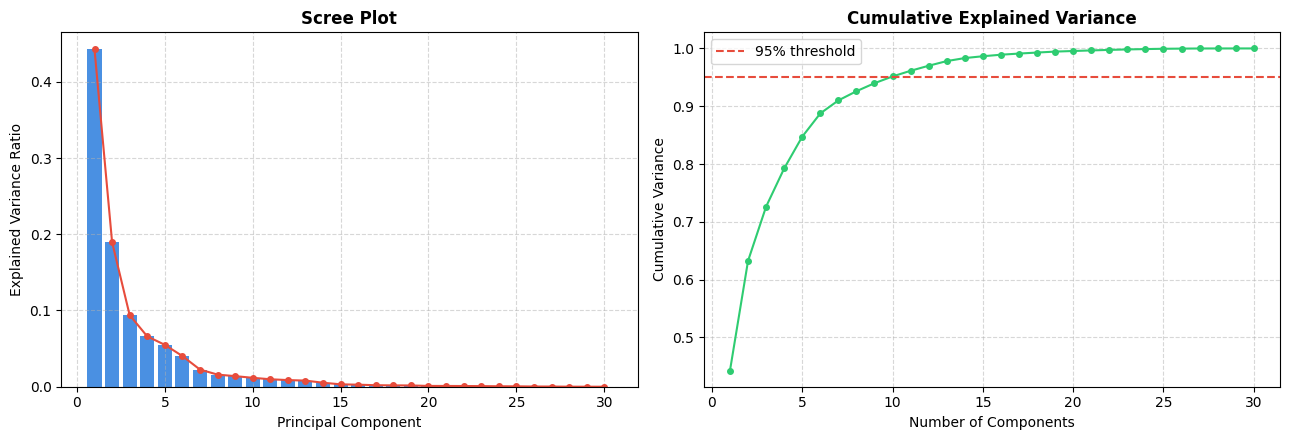

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pcs = np.arange(1, len(evr) + 1)
axes[0].bar(pcs, evr, color='#4a90e2', label='individual')
axes[0].plot(pcs, evr, 'o-', color='#e74c3c', markersize=4)
axes[0].set_title('Scree Plot', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[1].plot(pcs, cum_evr, 'o-', color='#2ecc71', markersize=4)
axes[1].axhline(0.95, color='#e74c3c', linestyle='--', label='95% threshold')
axes[1].set_title('Cumulative Explained Variance', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance')
axes[1].legend()
for ax in axes:
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**5. Selecting the Number of Components (Step 8)**

* The smallest $k$ with cumulative explained variance $\geq 95\%$ is chosen.
* The counts for 80%, 90% and 99% are also printed to show how fast the required $k$ grows near the top.

In [5]:
k = int(np.argmax(cum_evr >= 0.95) + 1)  # first count that crosses 95%
for t in [0.80, 0.90, 0.95, 0.99]:
    print(f'components for {t:.0%} variance : {int(np.argmax(cum_evr >= t) + 1)}')
print('=' * 50)
print(f'selected components : {k} of {X.shape[1]}')
print(f'retained variance   : {cum_evr[k - 1] * 100:.2f}%')
print('=' * 50)

components for 80% variance : 5
components for 90% variance : 7
components for 95% variance : 10
components for 99% variance : 17
selected components : 10 of 30
retained variance   : 95.16%


**6. Projecting into the Reduced Space (Step 9)**

* A new `PCA(n_components=k)` is fitted and `fit_transform()` computes the scores $Z = X_{std} W_k$, where $W_k$ holds the first $k$ eigenvectors.
* The first two components are plotted and coloured by the (unused) diagnosis to see how much class structure survives.

original shape : (569, 30)
reduced shape  : (569, 10)


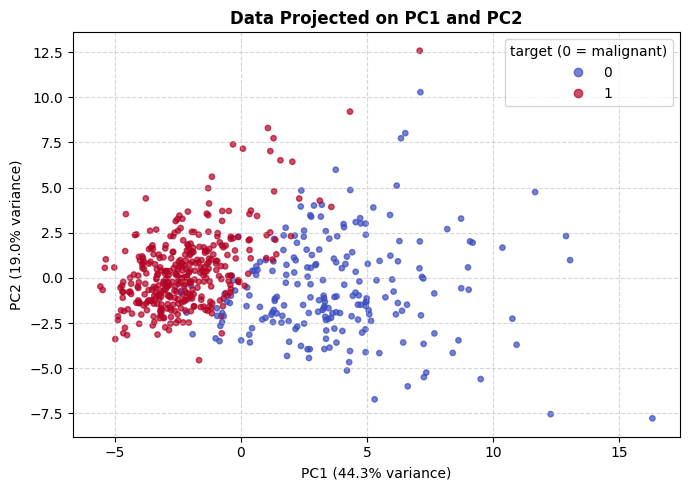

In [6]:
pca = PCA(n_components=k, random_state=42)
X_pca = pca.fit_transform(X_std)
print('original shape :', X_std.shape)
print('reduced shape  :', X_pca.shape)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', s=15, alpha=0.7)
ax.set_title('Data Projected on PC1 and PC2', fontsize=12, fontweight='bold')
ax.set_xlabel(f'PC1 ({evr[0] * 100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({evr[1] * 100:.1f}% variance)')
ax.legend(*sc.legend_elements(), title='target (0 = malignant)')
ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**7. Reconstruction & Reconstruction MSE (Steps 10–11)**

* `inverse_transform()` maps the scores back: $\hat{X} = Z W_k^T$ (plus the mean, which is 0 after scaling).
* **Reconstruction MSE:** $\text{MSE} = \frac{1}{n p} \sum_{i,j} (x_{ij} - \hat{x}_{ij})^2$. For standardized data this equals the fraction of variance thrown away, $1 - \text{cumulative EVR}$.
* MSE is also computed for every $k$ from 1 to 30, and one row (patient) is compared feature by feature with its reconstruction.

reconstruction mse (10 pcs) : 0.0484
1 - retained variance     : 0.0484
mse with 1, 2, 5, 10 pcs : [0.5573, 0.3676, 0.1527, 0.0484]
worst reconstructed features:
concave points error       0.1078
compactness error          0.0857
fractal dimension error    0.0783


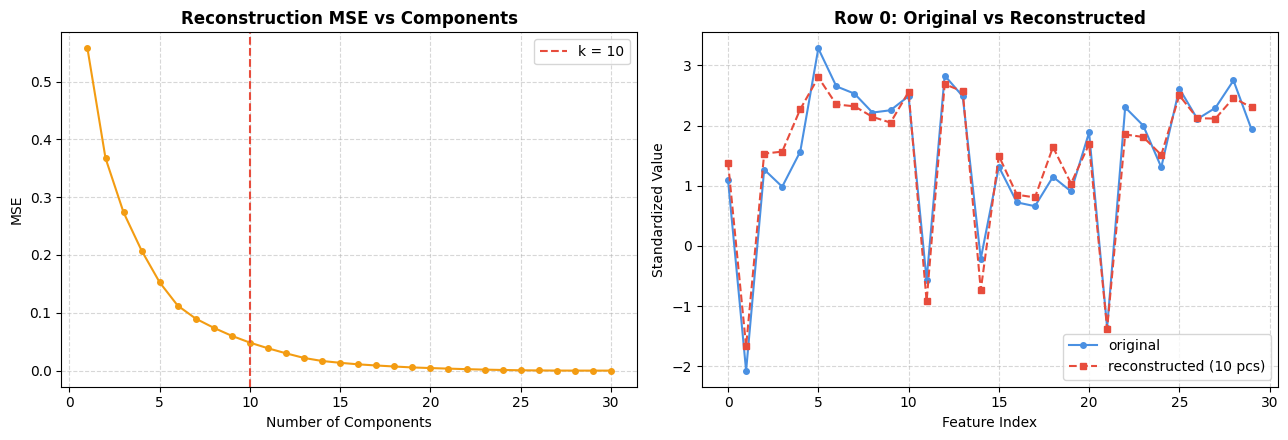

In [7]:
X_rec = pca.inverse_transform(X_pca)  # back to 30 standardized features
mse = mean_squared_error(X_std, X_rec)
print(f'reconstruction mse ({k} pcs) : {mse:.4f}')
print(f'1 - retained variance     : {1 - cum_evr[k - 1]:.4f}')  # should match mse
mse_list = []
for n in range(1, X.shape[1] + 1):
    p = PCA(n_components=n, random_state=42).fit(X_std)
    X_back = p.inverse_transform(p.transform(X_std))
    mse_list.append(mean_squared_error(X_std, X_back))
print('mse with 1, 2, 5, 10 pcs :',
      [round(mse_list[i - 1], 4) for i in [1, 2, 5, 10]])
feat_err = pd.Series(((X_std - X_rec) ** 2).mean(axis=0), index=X.columns)
print('worst reconstructed features:')
print(feat_err.sort_values(ascending=False).head(3).round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, X.shape[1] + 1), mse_list, 'o-', color='#f39c12',
             markersize=4)
axes[0].axvline(k, color='#e74c3c', linestyle='--', label=f'k = {k}')
axes[0].set_title('Reconstruction MSE vs Components', fontsize=12,
                  fontweight='bold')
axes[0].set_xlabel('Number of Components')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[1].plot(X_std[0], 'o-', color='#4a90e2', label='original', markersize=4)
axes[1].plot(X_rec[0], 's--', color='#e74c3c', label=f'reconstructed ({k} pcs)',
             markersize=4)
axes[1].set_title('Row 0: Original vs Reconstructed', fontsize=12,
                  fontweight='bold')
axes[1].set_xlabel('Feature Index')
axes[1].set_ylabel('Standardized Value')
axes[1].legend()
for ax in axes:
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**8. Principal Components, Eigenvectors & Eigenvalues (Objective 9)**

### **Theoretical Background:**
$$\Sigma = \frac{1}{n-1} X_{std}^T X_{std}, \qquad \Sigma \, w_j = \lambda_j \, w_j$$

Where:
* $\Sigma$ is the $30 \times 30$ covariance matrix of the standardized data.
* $w_j$ is the $j$-th **eigenvector**, i.e. the direction of principal component $j$.
* $\lambda_j$ is the **eigenvalue**, the variance of the data along $w_j$.

* The eigen-decomposition is done by hand with `np.linalg.eigh` and compared with sklearn's PCA (which uses SVD internally).

In [8]:
cov = np.cov(X_std, rowvar=False)
eig_vals, eig_vecs = np.linalg.eigh(cov)
order = np.argsort(eig_vals)[::-1]  # eigh gives ascending order
eig_vals, eig_vecs = eig_vals[order], eig_vecs[:, order]
print('top 5 eigenvalues (numpy) :', eig_vals[:5].round(4))
print('top 5 explained_variance_ :', pca_full.explained_variance_[:5].round(4))
same_dir = np.allclose(np.abs(eig_vecs[:, :k].T), np.abs(pca_full.components_[:k]))
print('eigenvectors = pca components (up to sign):', same_dir)
print(f'eigenvalue / sum = evr of pc1 : {eig_vals[0] / eig_vals.sum():.4f}')

top 5 eigenvalues (numpy) : [13.305   5.7014  2.8229  1.9841  1.6516]
top 5 explained_variance_ : [13.305   5.7014  2.8229  1.9841  1.6516]
eigenvectors = pca components (up to sign): True
eigenvalue / sum = evr of pc1 : 0.4427


**9. Inspecting Principal-Component Loadings (Step 12)**

* **Loadings** are the entries of each eigenvector (`pca.components_`); a large absolute value means the feature strongly shapes that component.
* The top features of PC1 and PC2 are listed by absolute loading, and a heatmap shows loadings for PC1–PC5.

top pc1 features (abs loading):
mean concave points     0.2609
mean concavity          0.2584
worst concave points    0.2509
mean compactness        0.2393
worst perimeter         0.2366

top pc2 features (abs loading):
mean fractal dimension     0.3666
fractal dimension error    0.2801
worst fractal dimension    0.2753
mean radius                0.2339
compactness error          0.2327

features with |loading| > 0.1 on pc1: 26


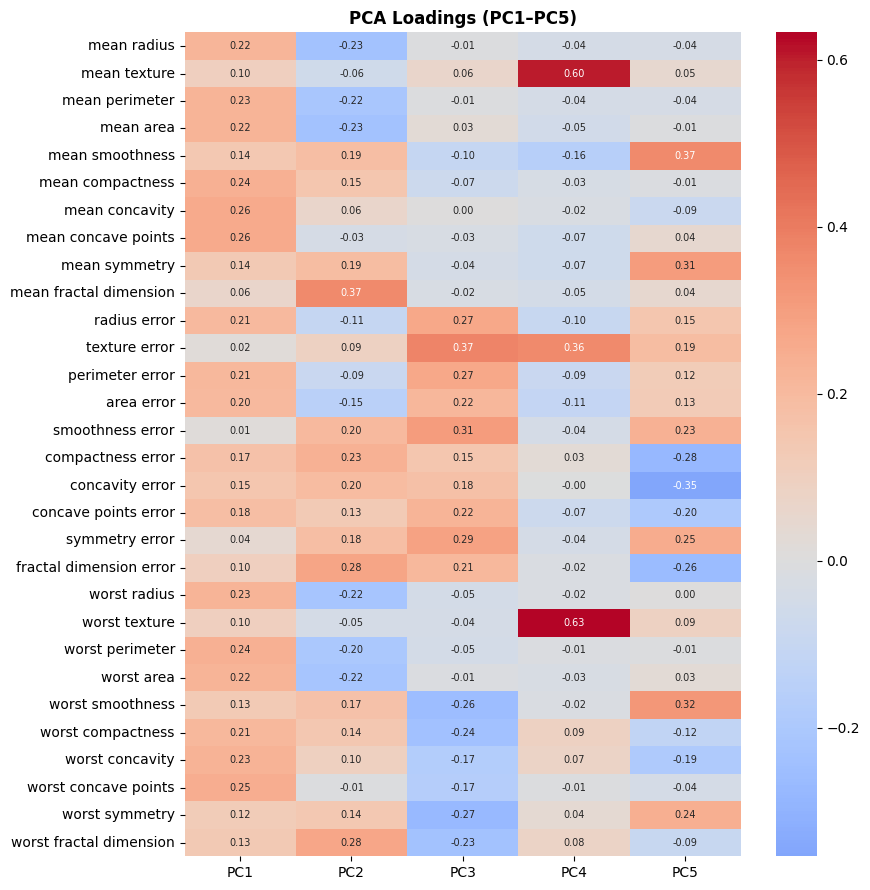

In [9]:
loadings = pd.DataFrame(pca.components_.T, index=X.columns,
                        columns=[f'PC{i + 1}' for i in range(k)])
pc1_top = loadings['PC1'].abs().sort_values(ascending=False).head(5)
pc2_top = loadings['PC2'].abs().sort_values(ascending=False).head(5)
print('top pc1 features (abs loading):')
print(pc1_top.round(4).to_string())
print('\ntop pc2 features (abs loading):')
print(pc2_top.round(4).to_string())
print('\nfeatures with |loading| > 0.1 on pc1:',
      (loadings['PC1'].abs() > 0.1).sum())
fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(loadings.iloc[:, :5], cmap='coolwarm', center=0, annot=True,
            fmt='.2f', annot_kws={'size': 7}, ax=ax)
ax.set_title('PCA Loadings (PC1–PC5)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**10. Observation Table, Information Loss & Interpretability (Steps 13–14)**

* The table follows the PDF's observation rows; every value is computed from the run above.
* Information loss is reported both as lost variance and as reconstruction MSE.

In [10]:
info_loss = 1 - cum_evr[k - 1]
obs = pd.DataFrame({
    'Observation': ['Number of original features', 'Number of selected components',
                    'Cumulative explained variance', 'Reconstruction MSE',
                    'Most influential features in PC1', 'Information loss'],
    'Result to record': [
        X.shape[1], k, f'{cum_evr[k - 1] * 100:.2f}%', f'{mse:.4f}',
               ', '.join(pc1_top.index[:3]),
               f'{info_loss * 100:.2f}% variance lost, mse = {mse:.4f}']})
print(obs.to_string(index=False))
print(f'\ndimension cut : {X.shape[1]} -> {k} '
      f'({(1 - k / X.shape[1]) * 100:.1f}% fewer features)')

                     Observation                                          Result to record
     Number of original features                                                        30
   Number of selected components                                                        10
   Cumulative explained variance                                                    95.16%
              Reconstruction MSE                                                    0.0484
Most influential features in PC1 mean concave points, mean concavity, worst concave points
                Information loss                         4.84% variance lost, mse = 0.0484

dimension cut : 30 -> 10 (66.7% fewer features)


### **Performance Summary & Comparison Table:**

| Observation | Result to record |
| :--- | :---: |
| **Number of original features** | 30 |
| **Number of selected components** | 10 |
| **Cumulative explained variance** | 95.16% |
| **Reconstruction MSE** | 0.0484 |
| **Most influential features in PC1** | mean concave points (0.2609), mean concavity (0.2584), worst concave points (0.2509) |
| **Information loss** | 4.84% of variance lost (MSE = 0.0484) with 66.7% fewer features |

---

### **Observations:**
* **Scree Plot:** PC1 alone explains 44.27% and PC2 18.97% of the variance; after about PC6 (88.76% cumulative) each extra component adds less than 2.3%, which is the elbow of the curve.
* **Component Count:** 5 components keep 80%, 7 keep 90%, 10 keep 95% and 17 are needed for 99%, so the last few percent of variance cost many extra dimensions.
* **Reconstruction Error:** MSE falls from 0.5573 (1 PC) to 0.3676 (2 PCs), 0.1527 (5 PCs) and 0.0484 (10 PCs), and the 10-PC MSE exactly equals $1 - 0.9516 = 0.0484$.
* **Where Information Is Lost:** the worst reconstructed features are `concave points error` (0.1078), `compactness error` (0.0857) and `fractal dimension error` (0.0783), the noisy standard-error features.
* **Eigenvectors:** the numpy eigenvalues of the covariance matrix (13.3050, 5.7014, 2.8229, ...) match `explained_variance_`, and the eigenvectors match `components_` up to sign.
* **Interpretability:** PC1 has 26 of 30 features with $|\text{loading}| > 0.1$, so it is a mix of almost everything (a general "size/concavity" axis) and has no single physical meaning like `mean radius` does.

---

### **Conclusion:**
* **PCA Works Well Here:** the 30 correlated features were compressed to **10 principal components** that retain **95.16%** of the variance, a 66.7% reduction in dimensions.
* **Standardization Matters:** scaling put every feature at mean 0 and std 1, so large-scale features like `mean area` (max 2501) did not dominate the components.
* **Low Information Loss:** the reconstruction MSE with 10 components is only **0.0484**, equal to the 4.84% discarded variance, and the PC1–PC2 projection still separates malignant and benign tumours visually.
* **Eigen Connection:** principal components are the eigenvectors of the covariance matrix and the eigenvalues are their variances, confirmed numerically against sklearn.
* **Selected Setting:** $k = 10$ components (95% variance) is chosen as the best trade-off between compression and information retention, accepting that the new features are linear mixes and harder to interpret than the original measurements. The fitted scaler + PCA are saved below.

**Saving the Scaler & PCA Model**

* The fitted `StandardScaler` and `PCA` are saved together with `joblib` so new rows can be projected the same way.

In [11]:
joblib.dump({'scaler': scaler, 'pca': pca}, 'pca_breast_cancer.pkl')
loaded = joblib.load('pca_breast_cancer.pkl')
X_new = loaded['pca'].transform(loaded['scaler'].transform(X))
print('pca saved and reloaded, same projection:', np.allclose(X_new, X_pca))

pca saved and reloaded, same projection: True


**11. Viva Questions & Comprehensive Answers**

### **Q1. What is PCA?**
**Answer:** **Principal Component Analysis** is an **unsupervised, linear dimensionality-reduction** technique. It finds new orthogonal axes (principal components) along which the data has the most variance, ordered from most to least. Projecting onto the first $k$ of them gives a compact representation that keeps most of the information. In this experiment PCA reduced 30 features to 10 while keeping 95.16% of the variance.

---

### **Q2. What is the first principal component?**
**Answer:** The **first principal component** is the unit direction $w_1$ along which the projected data has the **maximum variance**, i.e. $w_1 = \arg\max_{\lVert w \rVert = 1} w^T \Sigma w$. It is the eigenvector of the covariance matrix with the largest eigenvalue. Here PC1 had eigenvalue 13.305 and explained 44.27% of the variance, driven mostly by the concave-points and concavity features.

---

### **Q3. Why is standardization important in PCA?**
**Answer:** PCA maximises variance, and variance depends on the **units/scale** of each feature. Without scaling, a feature like `mean area` (values up to 2501) would have a huge variance and PC1 would just point along it, ignoring small-scale features like `mean smoothness`. `StandardScaler` gives every feature mean 0 and variance 1, so PCA works on the **correlation structure** and each feature gets a fair say.

---

### **Q4. What is explained variance ratio?**
**Answer:** The **explained variance ratio** of a component is the fraction of the total variance it captures: $\text{EVR}_j = \lambda_j / \sum_{i=1}^{p} \lambda_i$. All ratios add up to 1. It tells how important each component is; for example PC1 = 0.4427 and PC2 = 0.1897 in our run.

---

### **Q5. What is a scree plot?**
**Answer:** A **scree plot** shows the explained variance (or eigenvalue) of each principal component against its index, in decreasing order. It usually drops steeply and then flattens; the point where it bends, the **elbow**, suggests how many components are worth keeping. In our plot the curve flattens after about 6 components.

---

### **Q6. What does cumulative explained variance represent?**
**Answer:** **Cumulative explained variance** at $k$ is $\sum_{j=1}^{k} \text{EVR}_j$, the total share of the data's variance kept if the first $k$ components are used. It is used to pick $k$ with a threshold, e.g. 95%. Here it reached 95.16% at $k = 10$ and needed 17 components for 99%.

---

### **Q7. What is reconstruction error?**
**Answer:** **Reconstruction error** measures how much information is lost by compressing and then decompressing the data: $X$ is projected to $Z = X W_k$, mapped back with $\hat{X} = Z W_k^T$, and the error is $\text{MSE} = \frac{1}{np} \sum (x_{ij} - \hat{x}_{ij})^2$. For standardized data it equals the discarded variance fraction. Our 10-component reconstruction gave MSE = 0.0484, matching the 4.84% variance not kept.

---

### **Q8. What is the relationship between eigenvalues and PCA?**
**Answer:** PCA is the **eigen-decomposition of the covariance matrix** $\Sigma w_j = \lambda_j w_j$. The **eigenvectors** $w_j$ are the principal component directions (loadings), and the **eigenvalues** $\lambda_j$ are the variances along them, so sorting eigenvalues from largest to smallest ranks the components. We confirmed this: `np.linalg.eigh` gave eigenvalues 13.3050, 5.7014, ... identical to sklearn's `explained_variance_`.

---

### **Q9. Can PCA be used for classification?**
**Answer:** PCA itself is **not a classifier**: it is unsupervised and never uses the labels. But it is often used as a **preprocessing step** before a classifier (e.g. `Pipeline(StandardScaler, PCA, LogisticRegression)`) to remove noise and correlation, speed up training and reduce overfitting. The PC1–PC2 plot above shows malignant and benign tumours already fairly separated, so a classifier on the PCA features would work well; however, since PCA ignores labels, the highest-variance directions are not guaranteed to be the most discriminative (LDA targets that instead).

---

### **Q10. What is one disadvantage of PCA?**
**Answer:** A major disadvantage is **loss of interpretability**: each principal component is a linear combination of all original features, so it has no direct physical meaning. In our run 26 of 30 features had $|\text{loading}| > 0.1$ on PC1, so PC1 cannot be explained as one measurement. Other drawbacks are that PCA only captures **linear** relationships, is sensitive to **scaling and outliers**, and some information is always lost when components are dropped.